# Mass Points from Over-Triggering
Julian Hsu

Date Created: 2026 October 26

The purpose of this script is to understand what happens to the accuracy and bias of an experiment when we over trigger users into an experiment. Here over-triggering is defined as users who are equally added to both treatment and control groups in the data, even though they did not actually see the treatment and control experiences.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy import stats


from matplotlib import gridspec
import matplotlib.pyplot as plt
%matplotlib inline  


## Functions and Data Primitives

In [2]:
def dgp(N=1000
        , te=0.20
        , cmean=0.5
        , overtg_values = 0
        , overtg_amount= 100):
    ## Create treatment and control groups
    W = np.random.choice(2,N, p = [0.50, 0.50])

    ## Binary outcome
    Y = np.random.choice(2, N, p = [1-cmean, cmean])

    ## Create a lift in the treatment group.
    treatment_prob = cmean+te 
    Y[W==1] = np.random.choice(2
                               , len(Y[W==1])
                               , p=[1-treatment_prob, (treatment_prob) ])

    ## Create overtrigger flag
    otg = np.zeros(N)

    ## Add over trigger values and mass points
    if type(overtg_values)==list:
        for r in overtg_values:
            len_v = len(overtg_values)
            nnln = int(overtg_amount*1.0/len_v)
            W_tg = np.random.choice(2, nnln)
            Y_tg = np.zeros(nnln)+r
            otg_tg = np.ones(nnln)

            W = np.concatenate([W, W_tg])
            Y = np.concatenate([Y, Y_tg])
            otg = np.concatenate([otg, otg_tg])

    else:
        W_tg = np.random.choice(2, overtg_amount)
        Y_tg = np.zeros(overtg_amount)+overtg_values
        otg_tg = np.ones(overtg_amount)

        W = np.concatenate([W, W_tg])
        Y = np.concatenate([Y, Y_tg])
        otg = np.concatenate([otg, otg_tg])
        
    ## Put it all into a dataframe
    df_out = pd.DataFrame(data={'w':W, 'y':Y, 'otg':otg})
    return df_out 

def ttest(dt=None):
    return stats.ttest_ind(dt.loc[dt.w==1]['y'],dt.loc[dt.w==0]['y'] )


## Simulations
See what happens to the p-value as we increase the number of over-triggers and where they are placed.

In [14]:
cmean_list = [0.25, 0.95]
n_base = 1000 
over_tg_n_list = np.arange(1,1000+1,100)
over_tg_value_list = [0, 1, [0,1]]

sim_reps = 1000


In [15]:
i=0
df_sim = pd.DataFrame()
for s in range(sim_reps):
    for cd in cmean_list:
        for tg_n in over_tg_n_list:
            for tg_v in over_tg_value_list:
                x_df = dgp(N=n_base
                        , te=0.05
                        , cmean=cd
                        , overtg_values=tg_v, overtg_amount=tg_n)
                results_t_test = ttest(x_df)

                c_mean = x_df.loc[x_df.w==0]['y'].mean()
                t_mean = x_df.loc[x_df.w==1]['y'].mean()
                est_diff = t_mean - c_mean
                est_diff_perc = est_diff/c_mean

                row_ = pd.DataFrame(index=[i], data={'tg_n': tg_n,
                                                    'tg_v':str(tg_v),
                                                    'c_mean_v':cd,
                                                    'N':len(x_df),
                                                    'mean_c':c_mean,
                                                    'mean_t':t_mean,
                                                    'mean_overall': x_df['y'].mean(),
                                                    'diff':est_diff, 
                                                    'diff_perc':est_diff_perc, 
                                                    'tstat':results_t_test[0],
                                                    'pvalue':results_t_test[1]})
                df_sim = pd.concat([df_sim, row_])
                i+=1


df_sim['stat_sig'] = df_sim['pvalue']<0.05 

c:\Users\hsuju\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


In [16]:
res_sim = df_sim.groupby(['tg_n','tg_v','c_mean_v']).mean().round(2).reset_index()
res_sim_p05 = df_sim.groupby(['tg_n','tg_v','c_mean_v']).quantile(0.05).round(2).reset_index()
res_sim_p95= df_sim.groupby(['tg_n','tg_v','c_mean_v']).quantile(0.95).round(2).reset_index()

C:\Users\hsuju\AppData\Local\Temp\ipykernel_26536\1663049534.py:2: FutureWarning: Allowing bool dtype in DataFrameGroupBy.quantile is deprecated and will raise in a future version, matching the Series/DataFrame behavior. Cast to uint8 dtype before calling quantile instead.
  res_sim_p05 = df_sim.groupby(['tg_n','tg_v','c_mean_v']).quantile(0.05).round(2).reset_index()
C:\Users\hsuju\AppData\Local\Temp\ipykernel_26536\1663049534.py:3: FutureWarning: Allowing bool dtype in DataFrameGroupBy.quantile is deprecated and will raise in a future version, matching the Series/DataFrame behavior. Cast to uint8 dtype before calling quantile instead.
  res_sim_p95= df_sim.groupby(['tg_n','tg_v','c_mean_v']).quantile(0.95).round(2).reset_index()


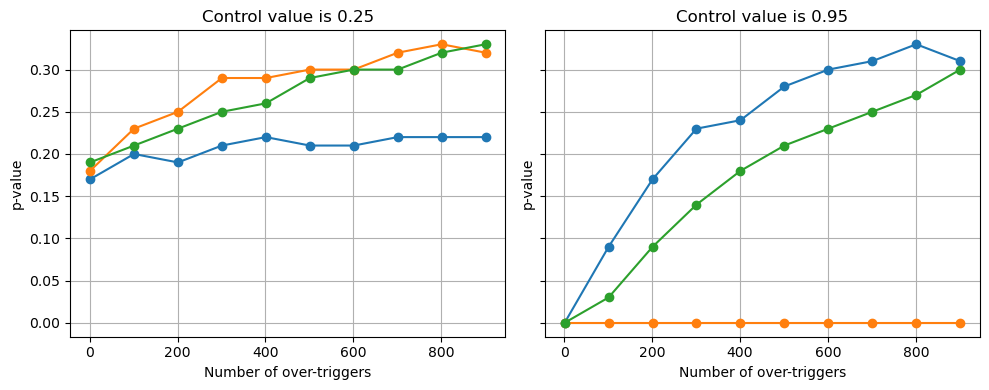

In [17]:
fig,ax = plt.subplots(ncols=len(cmean_list), nrows=1, sharey=True, figsize=(10,4))
for ci, ce in enumerate(cmean_list):
    for i, tg_v in enumerate(over_tg_value_list):

        dtax = res_sim.loc[(res_sim['tg_v']==str(tg_v)) & (res_sim['c_mean_v']==ce)]

        dtax05 = res_sim_p05.loc[res_sim_p05['tg_v']==str(tg_v)]
        dtax95 = res_sim_p95.loc[res_sim_p95['tg_v']==str(tg_v)]

        tye=ax[ci].plot(dtax.tg_n, dtax.pvalue,  marker='o', label=str(tg_v))


    ax[ci].grid()
    ax[ci].set_ylabel('p-value')
    ax[ci].set_xlabel('Number of over-triggers')
    # ax[ci].legend(title='Over-triggered value')
    ax[ci].set_title('Control value is {0:3.2f}'.format(ce))
plt.tight_layout()
plt.show()

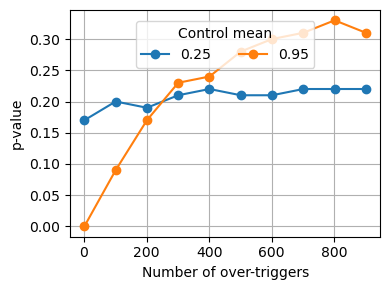

In [18]:
fig,ax = plt.subplots(ncols=1, nrows=1, sharey=True, figsize=(4,3))
for ci, ce in enumerate(cmean_list):
    tg_v = 0

    dtax = res_sim.loc[(res_sim['tg_v']==str(tg_v)) & (res_sim['c_mean_v']==ce)]

    tye=ax.plot(dtax.tg_n, dtax.pvalue,  marker='o', label=ce)

ax.legend(title='Control mean', loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=2)
ax.grid()
ax.set_ylabel('p-value')
ax.set_xlabel('Number of over-triggers')
plt.tight_layout()
plt.show()

## Let's do some math.
Focus on the standard error definition. We want to see how this changes as we add more over triggers at specific values. 
This should be represented as simultaneous increase in sample size *n* with decreases in *p* if we are adding more zeros.

Recall the standard error for the bernoulli distribution here is:
$$ se = \sqrt{ \dfrac{p(1-p)}{n} }  $$
$$ se = n^{-1/2} [ p(1-p) ]^{1/2} $$

This formulation is for a single group test. I am ignoring that that I am *really* doing a two group test. But 


The key here is to leverage the known relationship with adding more triggers with a value of zero. Suppose we start with:
* $n$ *real* data points
* $p$ probability from only the *real* data points
* $n_o$ over triggers at a value of zero.

Then the new probability average is $p_o$:
$$ p_o = \dfrac{np}{n+ n_o}$$

With that in mind, we can write the new standard error $se_o$:
$$se_o = \sqrt{  \dfrac{p_o ( 1-p_o)}{n + n_o} } = \sqrt{  \dfrac{ \frac{np}{n+n_o}\frac{n + n_o - np}{ n+ n_o} }{n + n_o}   }  $$

But we are missing the larger picture. We actually care about the t-statistic, which is the difference divided by the standard error. That difference changes too. Suppose further that:
* $d$ is the difference using only $n$ real data points

Then $d_o = \dfrac{d*n}{n+n_o}$ 

Therefore, the t-statistic is $\dfrac{d_o}{se_o}$. We want to see how the standard error, t-statistic , and p-value change not only over the baseline probability $p$ but also the number of over triggers at the value of zero $n_o$. 

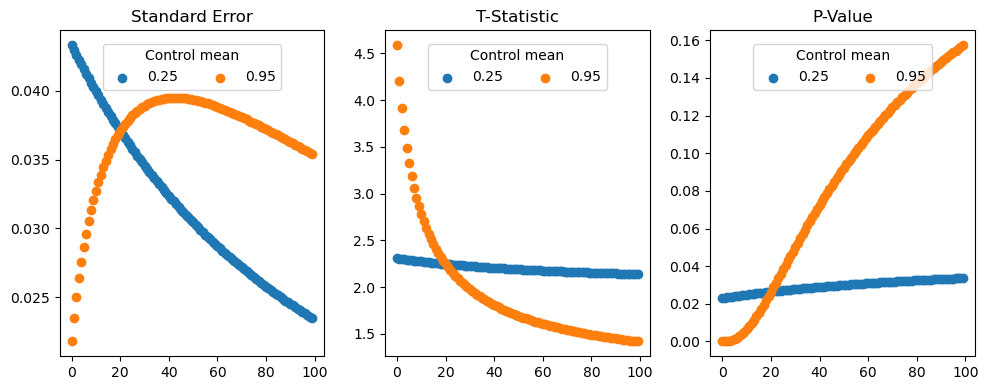

In [71]:
def se_o(n,p,no):
    po = (n*p)/(n+no)
    var_ = po*(1-po)/(n+no)
    return np.sqrt(var_)

def tstat_o(n,p,no):
    diff = 0.10
    se_ = se_o(n,p,no)
    diff_o = diff*n/(n+no)
    return diff_o / se_

from scipy import stats

def tstat_to_pvalue(t_stat, n):
    p_value = stats.t.sf(abs(t_stat), n-1) * 2
    return p_value 

n = 100
p1, p2 = 0.25, 0.95
no_list = np.arange(0,100, 1)
se_1o_list = [se_o(n,p1, no_) for no_ in no_list]
se_2o_list = [se_o(n,p2, no_) for no_ in no_list]

tstat_1o_list = [tstat_o(n,p1, no_) for no_ in no_list]
tstat_2o_list = [tstat_o(n,p2, no_) for no_ in no_list]

pvalue_1o_list = [tstat_to_pvalue(t_, n_) for t_, n_ in zip( tstat_1o_list, no_list+n) ]
pvalue_2o_list = [tstat_to_pvalue(t_, n_) for t_, n_ in zip( tstat_2o_list, no_list+n) ]


fig,ax = plt.subplots(ncols=3, nrows=1, figsize=(10,4))

ax[0].scatter(no_list, se_1o_list, label=p1)
ax[0].scatter(no_list, se_2o_list, label=p2)
ax[0].legend(title='Control mean', loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=2)
ax[0].set_title('Standard Error')

ax[1].scatter(no_list, tstat_1o_list, label=p1)
ax[1].scatter(no_list, tstat_2o_list, label=p2)
ax[1].legend(title='Control mean', loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=2)
ax[1].set_title('T-Statistic')

ax[2].scatter(no_list, pvalue_1o_list, label=p1)
ax[2].scatter(no_list, pvalue_2o_list, label=p2)
ax[2].legend(title='Control mean', loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=2)
ax[2].set_title('P-Value')


plt.tight_layout()
plt.show()